In [ ]:
!pip install import-ipynb

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import graip_dirigido_nuevo as gdn

## grafo 2

In [ ]:
# ==========================================
# 8. EJEMPLO DE PRUEBA (Adaptado para DiGraph)
# ==========================================
np.random.seed(0)

# 1. Creamos el grafo base de Karate Club y lo convertimos a dirigido (DiGraph)
# Opcional: puedes orientar las aristas de manera aleatoria o usar el directed nativo si existe
seed_G = nx.DiGraph(nx.karate_club_graph())

# 2. Asignar probabilidades a los nodos y arcos dirigidos
for u in seed_G.nodes():
    seed_G.nodes[u]['prob'] = 1.0

for u, v in seed_G.edges():
    seed_G[u][v]["prob"] = np.random.rand() * 0.7 + 0.3

G = seed_G
S = 1000      # Número de muestras (el paper original usa 10 000)
ng = 3       # ng=3 evalúa hasta 3 nodos (13 graphlets dirigidos)

# Ejecutamos el muestreo dirigido
SAMPLE = gdn.Sample_dirigido(G, S, ng, seed=0)

print(f"--- RESULTADOS DEL MUESTREO DIRIGIDO ---")
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}\n")

print("Promedios y desviaciones estándar de los Graphlets Dirigidos:")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:45s} Ec = {e:8.2f}  ± 2sc = {2*s:7.2f}")

In [ ]:
pesos_aristas = [seed_G[u][v]["prob"] for u, v,data in seed_G.edges(data=True)]

plt.figure(figsize=(10, 10))
plt.title('Grafo probabilista')
nx.draw_networkx_nodes(seed_G,nx.spring_layout(seed_G, seed=42,k=0.14),node_color="orange",node_size=100)
nx.draw_networkx_edges(seed_G,nx.spring_layout(seed_G, seed=42,k=0.14),alpha=pesos_aristas,edge_color='black',width=2)
plt.show()

In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gdn.GraphGenerator_dirigido(
    SAMPLE, ng, maxs=200000, node_step=5, w=0.5, maxrej=200, K=2, seed=0, verbose=2000
)

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.14),node_color="green",node_size=100)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.14),edge_color='black',width=1,arrowsize=10)
plt.show()

gdn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gdn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

## PPI Humano

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista4.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

In [ ]:
pesos_aristas = [G_core[u][v]["prob"]/2 for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=0.2,arrowsize=5)
plt.show()

In [ ]:
G = G_core
S = 100      # Número de muestras (el paper original usa 10 000)
ng = 3       # ng=3 evalúa hasta 3 nodos (13 graphlets dirigidos)

# Ejecutamos el muestreo dirigido
SAMPLE = gdn.Sample_dirigido(G, S, ng, seed=0)

print(f"--- RESULTADOS DEL MUESTREO DIRIGIDO ---")
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}\n")

print("Promedios y desviaciones estándar de los Graphlets Dirigidos:")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:45s} Ec = {e:8.2f}  ± 2sc = {2*s:7.2f}")

In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gdn.GraphGenerator_dirigido(
    SAMPLE, ng, maxs=100000, node_step=5, w=2/3, maxrej=100, K=2, seed=0, verbose=2000
)

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),edge_color='black',width=0.1,arrowsize=5)
plt.show()

gdn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gdn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)

## PPI Coli

In [ ]:
# 3. Cárgalo de vuelta a NetworkX
G_core = nx.read_graphml('/content/grafo_proteinas_probabilista6.graphml')
print(
    f"✨ ¡Grafo cargado exitosamente! Nodos: {G_core.number_of_nodes()},"
    f" Aristas: {G_core.number_of_edges()}"
)

✨ ¡Grafo cargado exitosamente! Nodos: 484, Aristas: 676


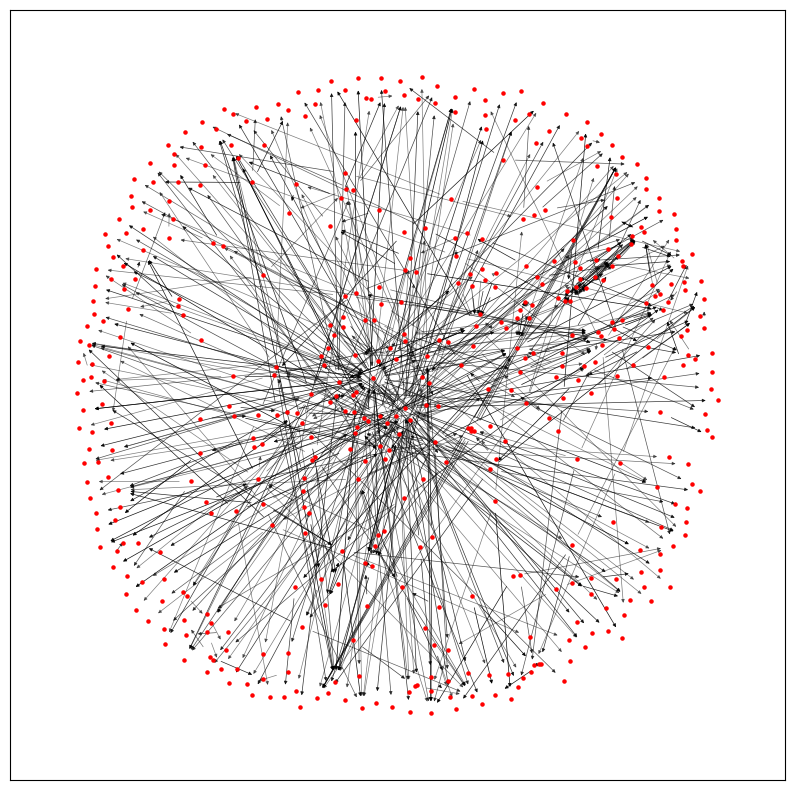

In [ ]:
pesos_aristas = [G_core[u][v]["prob"] for u, v,data in G_core.edges(data=True)]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_core,nx.spring_layout(G_core, seed=42,k=0.15),node_color="red",node_size=5)
nx.draw_networkx_edges(G_core,nx.spring_layout(G_core, seed=42,k=0.15),alpha=pesos_aristas,edge_color='black',width=0.5,arrowsize=5)
plt.show()

In [ ]:
G = G_core
S = 1000      # Número de muestras (el paper original usa 10 000)
ng = 3       # ng=3 evalúa hasta 3 nodos (13 graphlets dirigidos)

# Ejecutamos el muestreo dirigido
SAMPLE = gdn.Sample_dirigido(G, S, ng, seed=0)

print(f"--- RESULTADOS DEL MUESTREO DIRIGIDO ---")
print(f"En = {SAMPLE['En']:.2f} ± {SAMPLE['sn']:.2f}   Em = {SAMPLE['Em']:.2f} ± {SAMPLE['sm']:.2f}   CCg = {SAMPLE['CCg']:.3f}\n")

print("Promedios y desviaciones estándar de los Graphlets Dirigidos:")
for nombre, e, s in zip(SAMPLE["cat"]["nombres"], SAMPLE["Ec"], SAMPLE["sc"]):
    print(f"  {nombre:45s} Ec = {e:8.2f}  ± 2sc = {2*s:7.2f}")

--- RESULTADOS DEL MUESTREO DIRIGIDO ---
En = 321.56 ± 22.14   Em = 405.97 ± 26.37   CCg = 0.006

Promedios y desviaciones estándar de los Graphlets Dirigidos:
  Estrella de salida (Fuente central)           Ec =     0.00  ± 2sc =    0.00
  Graphlet k=3, 2 arcos (Desconocido)           Ec =     1.00  ± 2sc =    2.00
  Graphlet k=3, 2 arcos (Desconocido)           Ec =     2.00  ± 2sc =    4.00
  Graphlet k=3, 3 arcos (Desconocido)           Ec =     3.00  ± 2sc =    6.00
  Feed-Forward Loop (FFL parcial)               Ec =     4.00  ± 2sc =    8.00
  Graphlet k=3, 3 arcos (Desconocido)           Ec =     5.00  ± 2sc =   10.00
  Ciclo dirigido de 3 (C3)                      Ec =     6.00  ± 2sc =   12.00
  Tríada cuasi-completa A                       Ec =     7.00  ± 2sc =   14.00
  Graphlet k=3, 4 arcos (Desconocido)           Ec =     8.00  ± 2sc =   16.00
  Graphlet k=3, 4 arcos (Desconocido)           Ec =     9.00  ± 2sc =   18.00
  Graphlet k=3, 4 arcos (Desconocido)           Ec

In [ ]:
# Ejecutar GraphGenerator con los parámetros recomendados en el paper
# (node_step = 5, w = 2/3, maxrej = 0.02·Em, intervalo E ± 2s)
synthetic_H, history_data = gdn.GraphGenerator_dirigido(
    SAMPLE, ng, maxs=20000, node_step=5, w=0.5, maxrej=100, K=2, seed=0, verbose=2000,indexes=[0,1,2]
)

paso 2000: n=252, m=312, costo=0.1054
paso 4000: n=284, m=355, costo=0.0843
paso 6000: n=297, m=369, costo=0.0801
paso 8000: n=308, m=381, costo=0.0768
paso 10000: n=324, m=391, costo=0.0410
paso 12000: n=328, m=397, costo=0.0402
paso 14000: n=329, m=400, costo=0.0408
paso 16000: n=328, m=398, costo=0.0397
paso 18000: n=328, m=396, costo=0.0402
paso 20000: n=328, m=402, costo=0.0405
No convergió en 20000 pasos (costo final 0.0405).


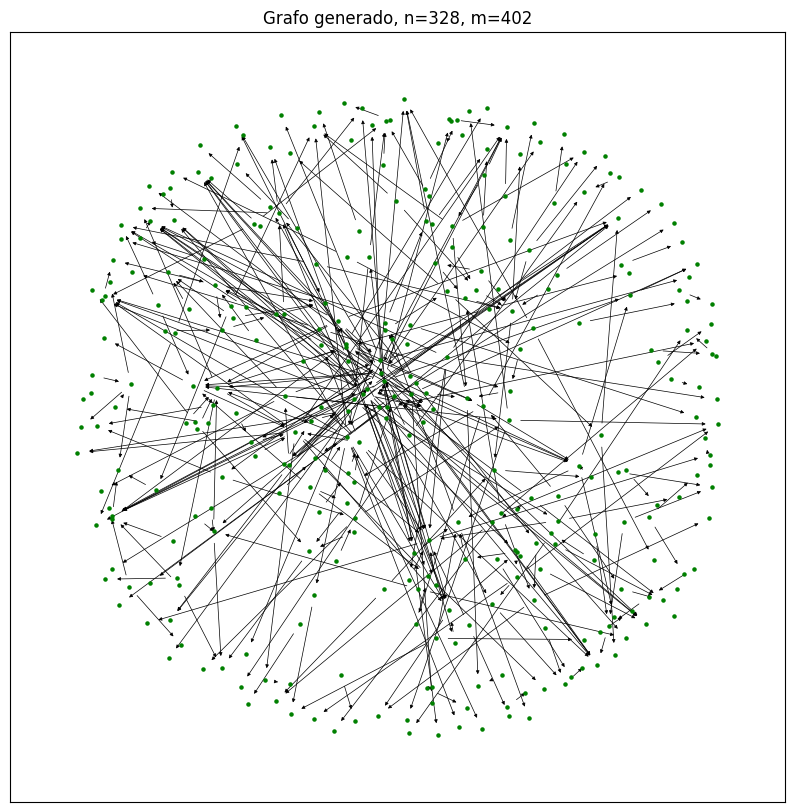

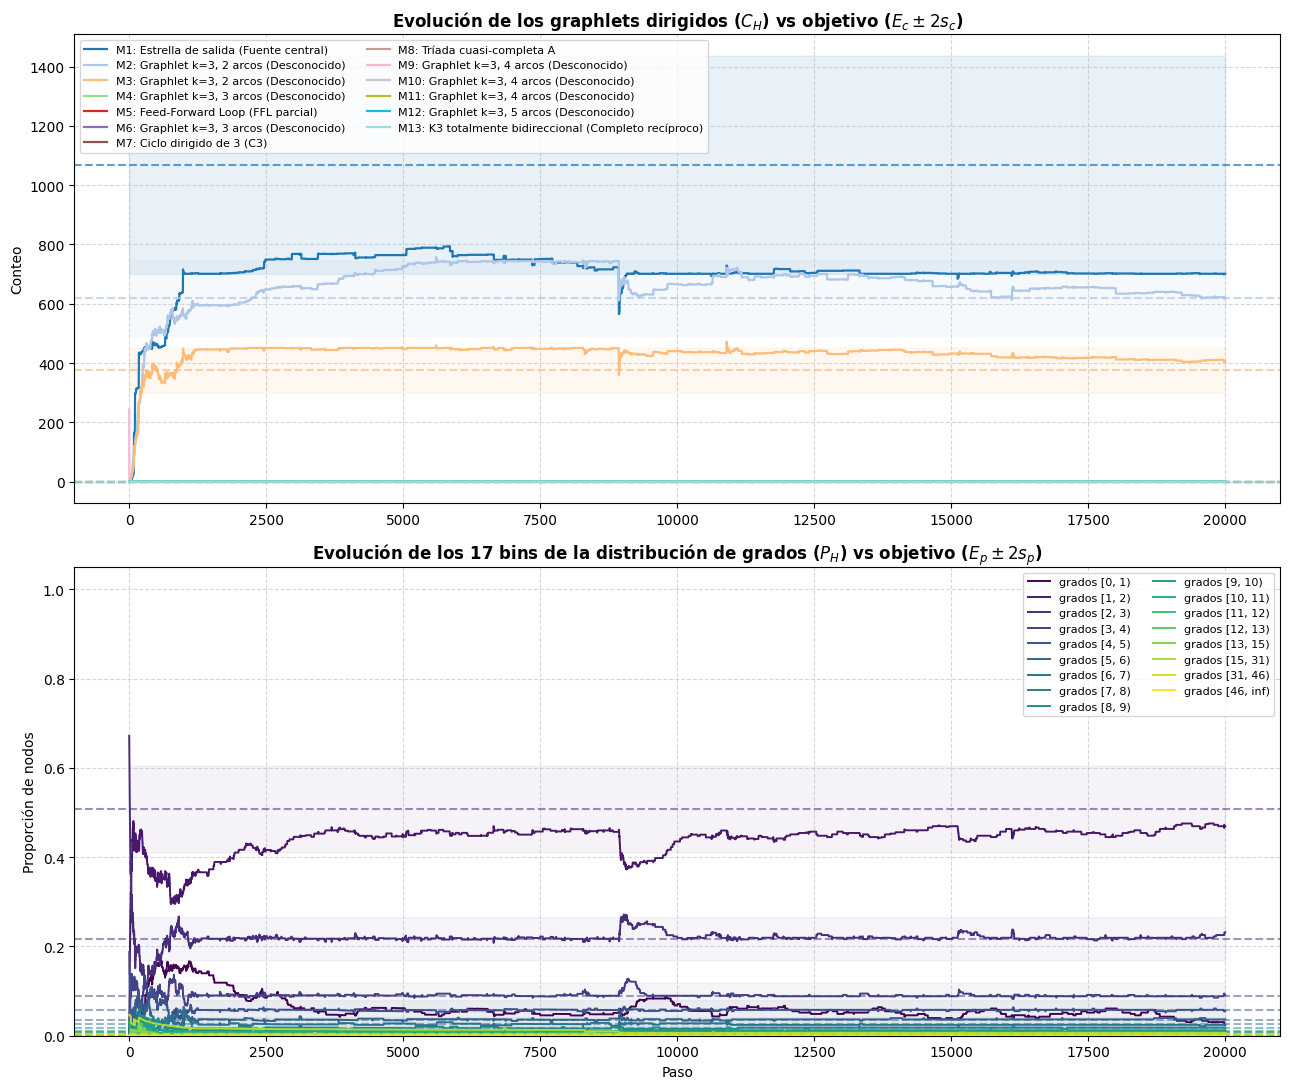

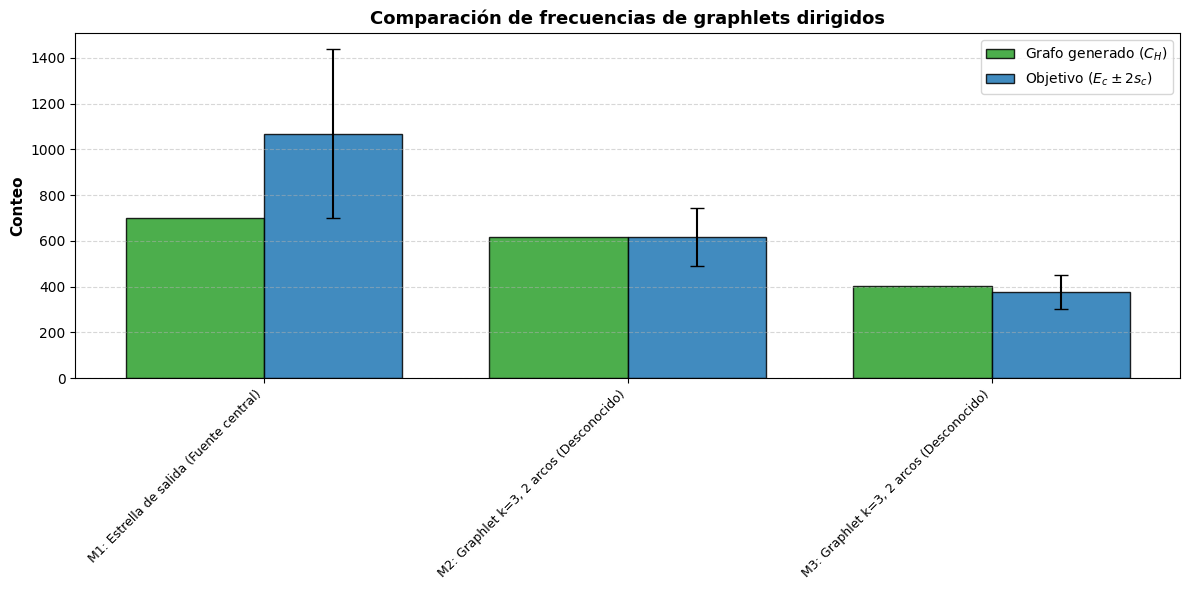

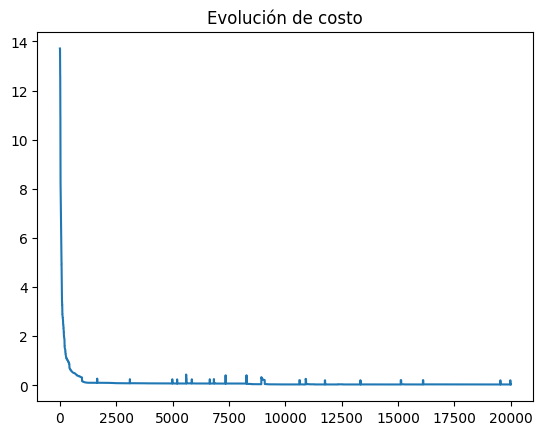

In [ ]:
n=history_data['n_trajectory'][-1]
m=history_data['m_trajectory'][-1]

plt.figure(figsize=(10, 10))
plt.title(f'Grafo generado, n={n}, m={m}')
nx.draw_networkx_nodes(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),node_color="green",node_size=5)
nx.draw_networkx_edges(synthetic_H,nx.spring_layout(synthetic_H, seed=42,k=0.15),edge_color='black',width=0.5,arrowsize=5)
plt.show()

gdn.plot_parameters_evolution(history_data)

final_CH_counts = history_data['CH_trajectory'][-1]
gdn.plot_graphlet_bar_comparison(final_CH_counts, history_data)
cost_evolution= history_data['cost_trajectory']
plt.title('Evolución de costo')
plt.plot(cost_evolution)